In [5]:
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
## Load the dataset and display the first 10 rows. How many rows and columns does it have?
df = pd.read_csv('dirty_cafe_sales.csv')
print(df.head(10))
print(f"Dataset shape: {df.shape}")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

  Transaction ID      Item Quantity Price Per Unit Total Spent  \
0    TXN_1961373    Coffee        2            2.0         4.0   
1    TXN_4977031      Cake        4            3.0        12.0   
2    TXN_4271903    Cookie        4            1.0       ERROR   
3    TXN_7034554     Salad        2            5.0        10.0   
4    TXN_3160411    Coffee        2            2.0         4.0   
5    TXN_2602893  Smoothie        5            4.0        20.0   
6    TXN_4433211   UNKNOWN        3            3.0         9.0   
7    TXN_6699534  Sandwich        4            4.0        16.0   
8    TXN_4717867       NaN        5            3.0        15.0   
9    TXN_2064365  Sandwich        5            4.0        20.0   

   Payment Method  Location Transaction Date  
0     Credit Card  Takeaway       2023-09-08  
1            Cash  In-store       2023-05-16  
2     Credit Card  In-store       2023-07-19  
3         UNKNOWN   UNKNOWN       2023-04-27  
4  Digital Wallet  In-store       2023

In [15]:
## Check for missing values in each column. Which column has the most missing values?
missning=df.isnull().sum()
print(missning)
most_missing_column = missning.idxmax()
print(f"Column with most missing values: {most_missing_column}")

Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64
Column with most missing values: Location


In [16]:
## Some cells contain the word ERROR or UNKNOWN instead of real data. Replace all of them with blank (NaN).
df.replace(['ERROR', 'UNKNOWN'], pd.NA, inplace=True)


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,NaN,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,NaN,NaN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,NaN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02


In [17]:
## The columns Quantity, Price Per Unit, and Total Spent should be numbers but are stored as text. Convert them to the correct type.
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Price Per Unit'] = pd.to_numeric(df['Price Per Unit'], errors='coerce')
df['Total Spent'] = pd.to_numeric(df['Total Spent'], errors='coerce')

In [19]:
## Drop any rows where Item or Transaction Date is missing. How many rows are left after dropping?
df.dropna(subset=['Item', 'Transaction Date'], inplace=True)
print(df.shape)

(8613, 8)


In [20]:
## What are the top 3 most sold items by total quantity?
df.groupby('Item')['Quantity'].sum().sort_values(ascending=False).head(3)

Item
Coffee    3251.0
Juice     3216.0
Salad     3161.0
Name: Quantity, dtype: float64

In [21]:
## What is the total revenue per item? Which item made the most money?
df.groupby('Item')['Total Spent'].sum().sort_values(ascending=False)

Item
Salad       15855.0
Sandwich    12328.0
Smoothie    12040.0
Juice        9540.0
Cake         9393.0
Coffee       6530.0
Tea          4453.5
Cookie       2922.0
Name: Total Spent, dtype: float64

In [22]:
## Which payment method is used the most? Show the count for each.
df['Payment Method'].value_counts()

Payment Method
Digital Wallet    1980
Cash              1956
Credit Card       1949
Name: count, dtype: int64

In [23]:
## Which location (In-store or Takeaway) generates more revenue on average per order?
df.groupby('Location')['Total Spent'].mean()

Location
In-store    9.102977
Takeaway    8.767713
Name: Total Spent, dtype: float64

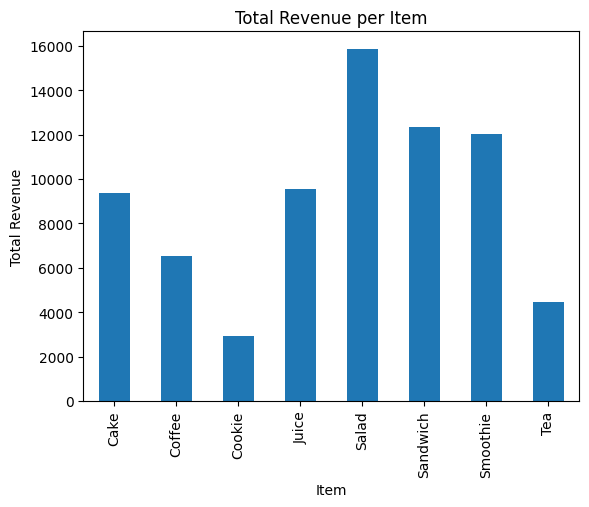

In [24]:
# # Draw a bar chart showing total revenue for each item. Add a title and axis labels.
revenue_per_item = df.groupby('Item')['Total Spent'].sum()
revenue_per_item.plot(kind='bar')
plt.title('Total Revenue per Item')
plt.xlabel('Item')
plt.ylabel('Total Revenue')
plt.show()

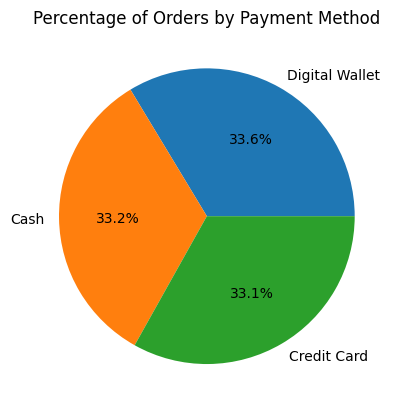

In [33]:
## Draw a pie chart showing the percentage of orders by payment method.use
payment_counts = df['Payment Method'].value_counts()
payment_counts.plot(kind='pie', autopct='%1.1f%%')
plt.title('Percentage of Orders by Payment Method')
plt.show()

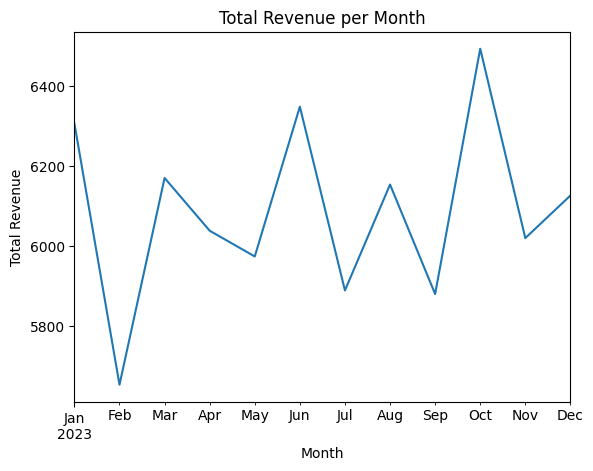

In [30]:
## Draw a line chart showing total revenue per month. Which month was the best?
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], errors='coerce')
df['Month'] = df['Transaction Date'].dt.to_period('M')
revenue_per_month = df.groupby('Month')['Total Spent'].sum()
revenue_per_month.plot(kind='line')
plt.title('Total Revenue per Month')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.show()

